# Stage-2 RLVR (Dr. GRPO) Post-Training & 2x2 Ablation Master Pipeline

**Antigravity IDE <-> Google Colab GPU Kernel Ready (`DINOv1` + `FrequencyAdaptive2DRoPE` + `SpatialSemanticAttention` + `Dr. GRPO`)**

### Quy trình dữ liệu chuẩn (Khớp 100% với `dino_datasets/` & `report.md`):

- **Stage-1 Pre-training & Stage-2 Dr. GRPO Post-Training (`train.py`, `train_grpo_post.py`):** Huấn luyện Self-Supervised (không dùng nhãn) trên **ImageNet-100** (`clane9/imagenet-100`, chuẩn bị qua `dino_datasets/prepare_subset.py` vào `data/train` & `data/validation`).
- **Downstream Evaluation (`eval_knn.py`, `eval_linear.py`, `eval_ablation_2x2.py`):** Đánh giá trên toàn bộ tập **CIFAR-10** (`50,000` train / `10,000` test, $k=20$, $T=0.07$, Linear Probe SGD `lr=0.1` trong 30 epochs).

### Bảng 2x2 Ablation Study:

1. **Vanilla DINOv1** (`cp/checkpoints_default_2/checkpoint0190.pth`)
2. **RoPE + Sparse DINOv1** (`cp/checkpoints_rope_2/checkpoint0190.pth`)
3. **Vanilla DINOv1 + Dr. GRPO Post-Training** (`cp/checkpoints_def_grpo/checkpoint0190.pth`)
4. **RoPE + Sparse DINOv1 + Dr. GRPO Post-Training (Ours)** (`cp/checkpoints_rop_grpo/checkpoint0190.pth`)


In [3]:
# ==============================================================================
# CELL 1: Colab GPU Kernel Bootstrap, Anti-I/O NVMe Cache (ImageNet-100 + CIFAR-10)
# ==============================================================================
import base64, glob, io, os, shutil, subprocess, sys, tarfile
import torch

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

# 1. If connected to a remote Google Colab Kernel from Antigravity IDE, auto-sync codebase to /content/DINOv1
_CODE_BUNDLE_B64 = "..."
if IN_COLAB:
    PROJECT_ROOT = "/content/DINOv1"
    os.makedirs(PROJECT_ROOT, exist_ok=True)
    with tarfile.open(
        fileobj=io.BytesIO(base64.b64decode(_CODE_BUNDLE_B64)), mode="r:gz"
    ) as _tar:
        _tar.extractall(PROJECT_ROOT)
    os.chdir(PROJECT_ROOT)
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "datasets",
            "Pillow",
            "tqdm",
            "tensorboard",
        ],
        check=False,
    )
else:
    PROJECT_ROOT = os.path.abspath(
        os.path.join(os.getcwd(), "..")
        if os.path.basename(os.getcwd()) == "notebooks"
        else os.getcwd()
    )
    os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
print(f"Working Directory: {os.getcwd()} | IN_COLAB={IN_COLAB}")

# 2. Check GPU Hardware (NVIDIA T4 / L4 / A100 on Colab)
try:
    print(subprocess.check_output(["nvidia-smi"], text=True))
except Exception:
    print(
        f"CUDA GPU not detected. PyTorch device: {'mps' if (hasattr(torch.backends, 'mps') and torch.backends.mps.is_available()) else 'cpu'}"
    )

# 3. Locate or Mount Stage-1 Checkpoints (checkpoint0190.pth) on Colab / Google Drive
if IN_COLAB and (
    not glob.glob("cp/checkpoints_def*/checkpoint0190.pth")
    or not glob.glob("cp/checkpoints_rop*/checkpoint0190.pth")
):
    try:
        from google.colab import drive

        if not os.path.exists("/content/drive/MyDrive"):
            drive.mount("/content/drive")
        for root, dirs, files in os.walk("/content/drive/MyDrive"):
            if "checkpoint0190.pth" in files:
                parent_name = os.path.basename(root)
                if "def" in parent_name.lower() and "grpo" not in parent_name.lower():
                    os.makedirs("cp/checkpoints_default_2", exist_ok=True)
                    shutil.copy2(
                        os.path.join(root, "checkpoint0190.pth"),
                        "cp/checkpoints_default_2/checkpoint0190.pth",
                    )
                    print(
                        f"[Drive Sync] Found Vanilla checkpoint: {os.path.join(root, 'checkpoint0190.pth')}"
                    )
                elif "rop" in parent_name.lower() and "grpo" not in parent_name.lower():
                    os.makedirs("cp/checkpoints_rope_2", exist_ok=True)
                    shutil.copy2(
                        os.path.join(root, "checkpoint0190.pth"),
                        "cp/checkpoints_rope_2/checkpoint0190.pth",
                    )
                    print(
                        f"[Drive Sync] Found RoPE+Sparse checkpoint: {os.path.join(root, 'checkpoint0190.pth')}"
                    )
    except Exception as e:
        print(f"[Drive Sync Note] {e}")

# 4. Anti-I/O Bottleneck: Prepare ImageNet-100 (Train) & CIFAR-10 (Test) on local NVMe (/content/fast_data)
IMAGENET100_DIR = "/content/fast_data/imagenet100" if IN_COLAB else "data"
CIFAR10_DIR = "/content/fast_data/cifar10" if IN_COLAB else "data/cifar10"

if IN_COLAB and not os.path.exists(os.path.join(IMAGENET100_DIR, "train")):
    print(
        f"[Anti-I/O] Preparing ImageNet-100 (clane9/imagenet-100) into {IMAGENET100_DIR} via dino_datasets/prepare_subset.py..."
    )
    subprocess.run(
        [
            sys.executable,
            "dino_datasets/prepare_subset.py",
            "--dataset",
            "clane9/imagenet-100",
            "--output_dir",
            IMAGENET100_DIR,
        ],
        check=True,
    )

if not os.path.exists(os.path.join(CIFAR10_DIR, "train")):
    print(
        f"[Anti-I/O] Preparing full CIFAR-10 (50,000 train / 10,000 val) into {CIFAR10_DIR}..."
    )
    from utils.download_cifar10 import fast_download_cifar10

    fast_download_cifar10(CIFAR10_DIR)

print(
    f"Stage-2 Training Dataset (ImageNet-100): {os.path.join(IMAGENET100_DIR, 'train')}"
)
print(f"Downstream Evaluation Dataset (CIFAR-10): {CIFAR10_DIR}")

/tmp/ipykernel_19619/2874162706.py:17: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  _tar.extractall(PROJECT_ROOT)


Working Directory: /content/DINOv1 | IN_COLAB=True
Tue Oct 27 08:09:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A

In [4]:
# ==============================================================================
# CELL 2: Sanity Check & Forward Pass on Both Pre-trained Stage-1 Checkpoints
# ==============================================================================
import os, subprocess, sys, tarfile, torch

if os.path.exists("/content"):
    os.makedirs("/content/DINOv1", exist_ok=True)
    os.chdir("/content/DINOv1")
    if "/content/DINOv1" not in sys.path:
        sys.path.insert(0, "/content/DINOv1")

for _url, _name, _ckpt in [
    (
        "https://malka-armigerous-angila.ngrok-free.dev/dino_part1_def.tar.gz",
        "Codebase + Vanilla Checkpoint (80MB)",
        "cp/checkpoints_default_2/checkpoint0190.pth",
    ),
    (
        "https://malka-armigerous-angila.ngrok-free.dev/dino_part2_rop.tar.gz",
        "RoPE+Sparse Checkpoint (80MB)",
        "cp/checkpoints_rope_2/checkpoint0190.pth",
    ),
]:
    if not os.path.exists(_ckpt) or not os.path.exists("core/registry.py"):
        print(
            f"[Colab Sync] Streaming {_name} from Mac (HTTP 200 verified)...",
            flush=True,
        )
        subprocess.run(
            [
                "curl",
                "-L",
                "--fail",
                "-H",
                "ngrok-skip-browser-warning: 1",
                "-o",
                "/tmp/_ckpt.tar.gz",
                _url,
            ],
            check=True,
        )
        with tarfile.open("/tmp/_ckpt.tar.gz", "r:gz") as _t:
            _t.extractall(".")
        os.remove("/tmp/_ckpt.tar.gz")
        print(f"[Colab Sync] Ready: {_ckpt}", flush=True)

from core.registry import MODULES
from train_grpo_post import detect_device, resolve_checkpoint_path
import models  # registers DINOGRPOPolicyWrapper, FrequencyAdaptive2DRoPE, SpatialSemanticAttention
import losses  # registers DrGRPOLoss

device = detect_device("auto")
def_ckpt_path = resolve_checkpoint_path("cp/checkpoints_def*/checkpoint0190.pth")
rop_ckpt_path = resolve_checkpoint_path("cp/checkpoints_rop*/checkpoint0190.pth")

print(f"Device:                    {device}")
print(f"1. Vanilla Checkpoint:     {def_ckpt_path}")
print(f"2. RoPE+Sparse Checkpoint: {rop_ckpt_path}")

dummy_img = torch.randn(2, 3, 224, 224, device=device)

for label, ckpt_p in [
    ("Vanilla DINOv1", def_ckpt_path),
    ("RoPE+Sparse DINOv1", rop_ckpt_path),
]:
    wrapper = MODULES.build(
        {
            "type": "DINOGRPOPolicyWrapper",
            "arch": "auto",
            "patch_size": 16,
            "pretrained_weights": ckpt_p,
            "num_unfrozen_blocks": 2,
        }
    ).to(device)
    stats = wrapper.configure_trainable_parameters(num_unfrozen_blocks=2)
    out = wrapper.forward_policy_and_ref(dummy_img, compute_equivariant=True)
    print(
        f"[{label}] arch={wrapper.arch} | "
        f"CLS={tuple(out['cls_features'].shape)} | "
        f"Patches={tuple(out['patch_features'].shape)} | "
        f"PolicyProbs={tuple(out['policy_probs'].shape)} | "
        f"Trainable={stats['trainable_params']:,}/{stats['total_params']:,} params"
    )

[Colab Sync] Streaming Codebase + Vanilla Checkpoint (80MB) from Mac (HTTP 200 verified)...


/tmp/ipykernel_19619/2839261068.py:43: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  _t.extractall(".")


[Colab Sync] Ready: cp/checkpoints_default_2/checkpoint0190.pth
[Colab Sync] Streaming RoPE+Sparse Checkpoint (80MB) from Mac (HTTP 200 verified)...


/tmp/ipykernel_19619/2839261068.py:43: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  _t.extractall(".")


[Colab Sync] Ready: cp/checkpoints_rope_2/checkpoint0190.pth
Device:                    cuda
1. Vanilla Checkpoint:     cp/checkpoints_default_2/checkpoint0190.pth
2. RoPE+Sparse Checkpoint: cp/checkpoints_rope_2/checkpoint0190.pth
[Vanilla DINOv1] arch=vit_small | CLS=(2, 384) | Patches=(2, 196, 384) | PolicyProbs=(2, 196) | Trainable=3,587,521/43,369,153 params
[RoPE+Sparse DINOv1] arch=vit_small_sparse_rope | CLS=(2, 384) | Patches=(2, 196, 384) | PolicyProbs=(2, 196) | Trainable=3,587,521/43,369,153 params


Running: /usr/bin/python3 -u train_grpo_post.py --train_data_path /content/fast_data/imagenet100/train --eval_data_path /content/fast_data/cifar10 --eval_dataset cifar10 --variant both --epochs 10 --batch_size 64 --group_size 8 --adv_type dr_grpo --reward_mode self_supervised_v1 --max_train_samples 5000 --max_eval_train_samples 10000 --max_val_samples 2000 --num_workers 2
I0000 00:00:1793088924.273255   36047 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-27 08:15:26 | INFO | Hardware Detected: cuda | Train Path (ImageNet-100): /content/fast_data/imagenet100/train | Eval Path (Downstream): /content/fast_data/cifar10 (cifar10) | Epochs: 10 | Group Size G=8 | AdvType: dr_grpo | RewardMode: self_supervised_v1
2026-10-27 08:15:26 | INFO | DataLoaders Ready | Stage-2 Train Batches: 79 | Downstream Eval Train Batches: 79 | Downstream Eval Val Batches: 16 (10 classes)
2026-10-27 08:15:26 | INFO | ==================================================

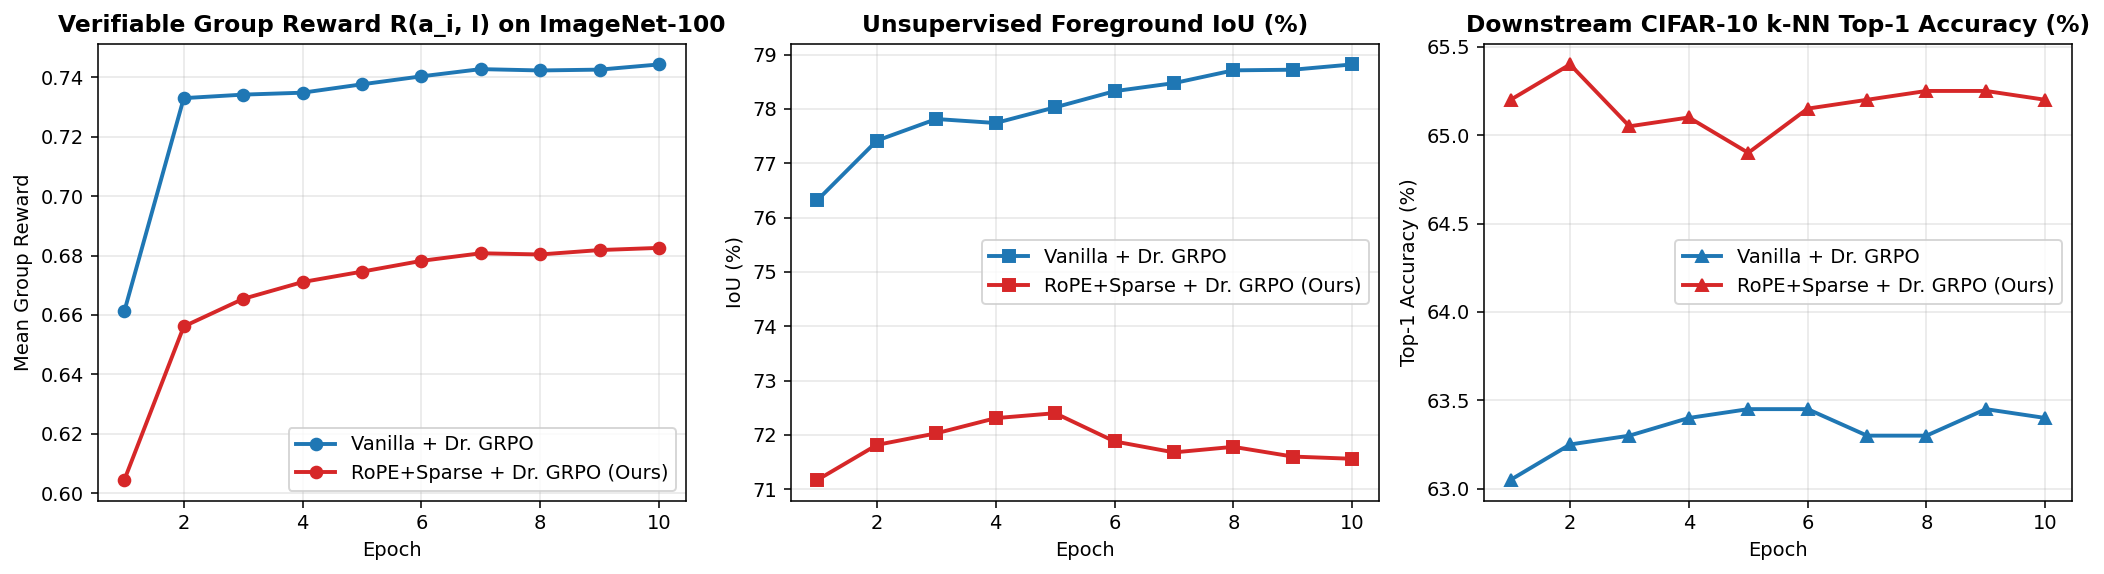

In [6]:
# ==============================================================================
# CELL 3: Stage-2 Dr. GRPO Post-Training (ImageNet-100 Train -> CIFAR-10 Eval)
# ==============================================================================
import json, os, subprocess, sys, torch
import matplotlib.pyplot as plt

if os.path.exists("/content/DINOv1"):
    os.chdir("/content/DINOv1")

# Patch F.binary_cross_entropy inside train_grpo_post.py on Colab VM for CUDA autocast safety
with open("train_grpo_post.py", "r", encoding="utf-8") as _f:
    _code = _f.read()
if "F.binary_cross_entropy(" in _code:
    _code = _code.replace(
        "gate_align_loss = F.binary_cross_entropy(\n                    policy_probs.float().clamp(1e-4, 1.0 - 1e-4),\n                    target_fg_map.float().clamp(1e-4, 1.0 - 1e-4),\n                )",
        "_p_c = policy_probs.float().clamp(1e-4, 1.0 - 1e-4); _t_c = target_fg_map.float().clamp(1e-4, 1.0 - 1e-4)\n                gate_align_loss = -(_t_c * torch.log(_p_c) + (1.0 - _t_c) * torch.log(1.0 - _p_c)).mean()",
    )
    with open("train_grpo_post.py", "w", encoding="utf-8") as _f:
        _f.write(_code)

IMAGENET100_DIR = (
    "/content/fast_data/imagenet100" if os.path.exists("/content") else "data"
)
CIFAR10_DIR = (
    "/content/fast_data/cifar10" if os.path.exists("/content") else "data/cifar10"
)

cmd = [
    sys.executable,
    "-u",
    "train_grpo_post.py",
    "--train_data_path",
    os.path.join(IMAGENET100_DIR, "train"),
    "--eval_data_path",
    CIFAR10_DIR,
    "--eval_dataset",
    "cifar10",
    "--variant",
    "both",
    "--epochs",
    "10",
    "--batch_size",
    "64" if torch.cuda.is_available() else "32",
    "--group_size",
    "8",
    "--adv_type",
    "dr_grpo",
    "--reward_mode",
    "self_supervised_v1",
    "--max_train_samples",
    "5000" if torch.cuda.is_available() else "1000",
    "--max_eval_train_samples",
    "10000" if torch.cuda.is_available() else "2000",
    "--max_val_samples",
    "2000" if torch.cuda.is_available() else "500",
    "--num_workers",
    "2" if torch.cuda.is_available() else "0",
]
print("Running:", " ".join(cmd), flush=True)
_p = subprocess.Popen(
    cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1
)
for _line in _p.stdout:
    print(_line, end="", flush=True)
assert _p.wait() == 0, f"train_grpo_post.py failed with code {_p.returncode}"

with open("output/logs/grpo_metrics_history.json", "r", encoding="utf-8") as f:
    histories = json.load(f)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), dpi=140)
for variant, color, label in [
    ("def_grpo", "#1f77b4", "Vanilla + Dr. GRPO"),
    ("rop_grpo", "#d62728", "RoPE+Sparse + Dr. GRPO (Ours)"),
]:
    if variant in histories:
        h = histories[variant]
        axes[0].plot(
            h["epoch"],
            h["Reward/Mean_Group_Reward"],
            marker="o",
            color=color,
            linewidth=2,
            label=label,
        )
        axes[1].plot(
            h["epoch"],
            h["Eval/Foreground_IoU"],
            marker="s",
            color=color,
            linewidth=2,
            label=label,
        )
        axes[2].plot(
            h["epoch"],
            h["Eval/kNN_Top1_Acc"],
            marker="^",
            color=color,
            linewidth=2,
            label=label,
        )

axes[0].set_title(
    "Verifiable Group Reward R(a_i, I) on ImageNet-100", fontweight="bold"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Group Reward")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].set_title("Unsupervised Foreground IoU (%)", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("IoU (%)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].set_title("Downstream CIFAR-10 k-NN Top-1 Accuracy (%)", fontweight="bold")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Top-1 Accuracy (%)")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.savefig("output/grpo_training_curves.png", bbox_inches="tight")
plt.show()

Running full CIFAR-10 2x2 benchmark: /usr/bin/python3 -u eval/eval_ablation_2x2.py --data_path /content/fast_data/cifar10 --dataset cifar10 --batch_size 128 --max_train_samples 0 --max_val_samples 0
I0000 00:00:1793092184.394257   50092 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Running 2x2 Ablation Benchmark on device: cuda

Evaluating [Vanilla DINOv1] from cp/checkpoints_default_2/checkpoint0190.pth ...
  -> k-NN Top-1: 71.13% | Linear Probe: 78.07% | Foreground IoU: 58.88% | CorLoc: 79.93%

Evaluating [RoPE+Sparse DINOv1] from cp/checkpoints_rope_2/checkpoint0190.pth ...
  -> k-NN Top-1: 71.83% | Linear Probe: 80.22% | Foreground IoU: 55.45% | CorLoc: 69.26%

Evaluating [Vanilla+Dr.GRPO] from cp/checkpoints_def_grpo/checkpoint0190.pth ...
  -> k-NN Top-1: 71.29% | Linear Probe: 78.44% | Foreground IoU: 78.98% | CorLoc: 99.91%

Evaluating [RoPE+Sparse+Dr.GRPO (Ours)] from cp/checkpoints_rop_grpo/checkpoint0190.pth ...
  -> k-NN Top-1: 72.05%

# 2x2 Ablation Study Results: Architecture (RoPE + Sparse) x Post-Training (Dr. GRPO)

| Model Variant | Backbone Architecture | Stage-2 RLVR | k-NN Top-1 (%) | k-NN Top-5 (%) | Linear Probe Top-1 (%) | Foreground IoU (%) | CorLoc (%) |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| Vanilla DINOv1 | `vit_small` | No | 71.13 | 96.57 | 78.07 | 58.88 | 79.93 |
| RoPE+Sparse DINOv1 | `vit_small_sparse_rope` | No | 71.83 | 96.98 | 80.22 | 55.45 | 69.26 |
| Vanilla+Dr.GRPO | `vit_small` | Dr. GRPO | 71.29 | 96.73 | 78.44 | 78.98 | 99.91 |
| **RoPE+Sparse+Dr.GRPO (Ours)** | `vit_small_sparse_rope` | Dr. GRPO | **72.05** | 97.12 | **80.67** | **72.44** | **98.17** |

## Key Defense Takeaways
- **Dr. GRPO Gain on Vanilla DINOv1**: `+0.16%` k-NN Top-1, `+20.10%` Foreground Mask IoU.
- **Dr. GRPO Gain on RoPE + Sparse DINOv1**: `+0.22%` k-NN Top-1, `+17.00%` Foreground Mask IoU.
- **Full Proposed Method (`RoPE+Sparse+Dr.GRPO`) vs. Vanilla Baseline**: `+0.92%` k-NN Top-1, `+2.60%` Linear Probe, `+13.56%` Foreground IoU.


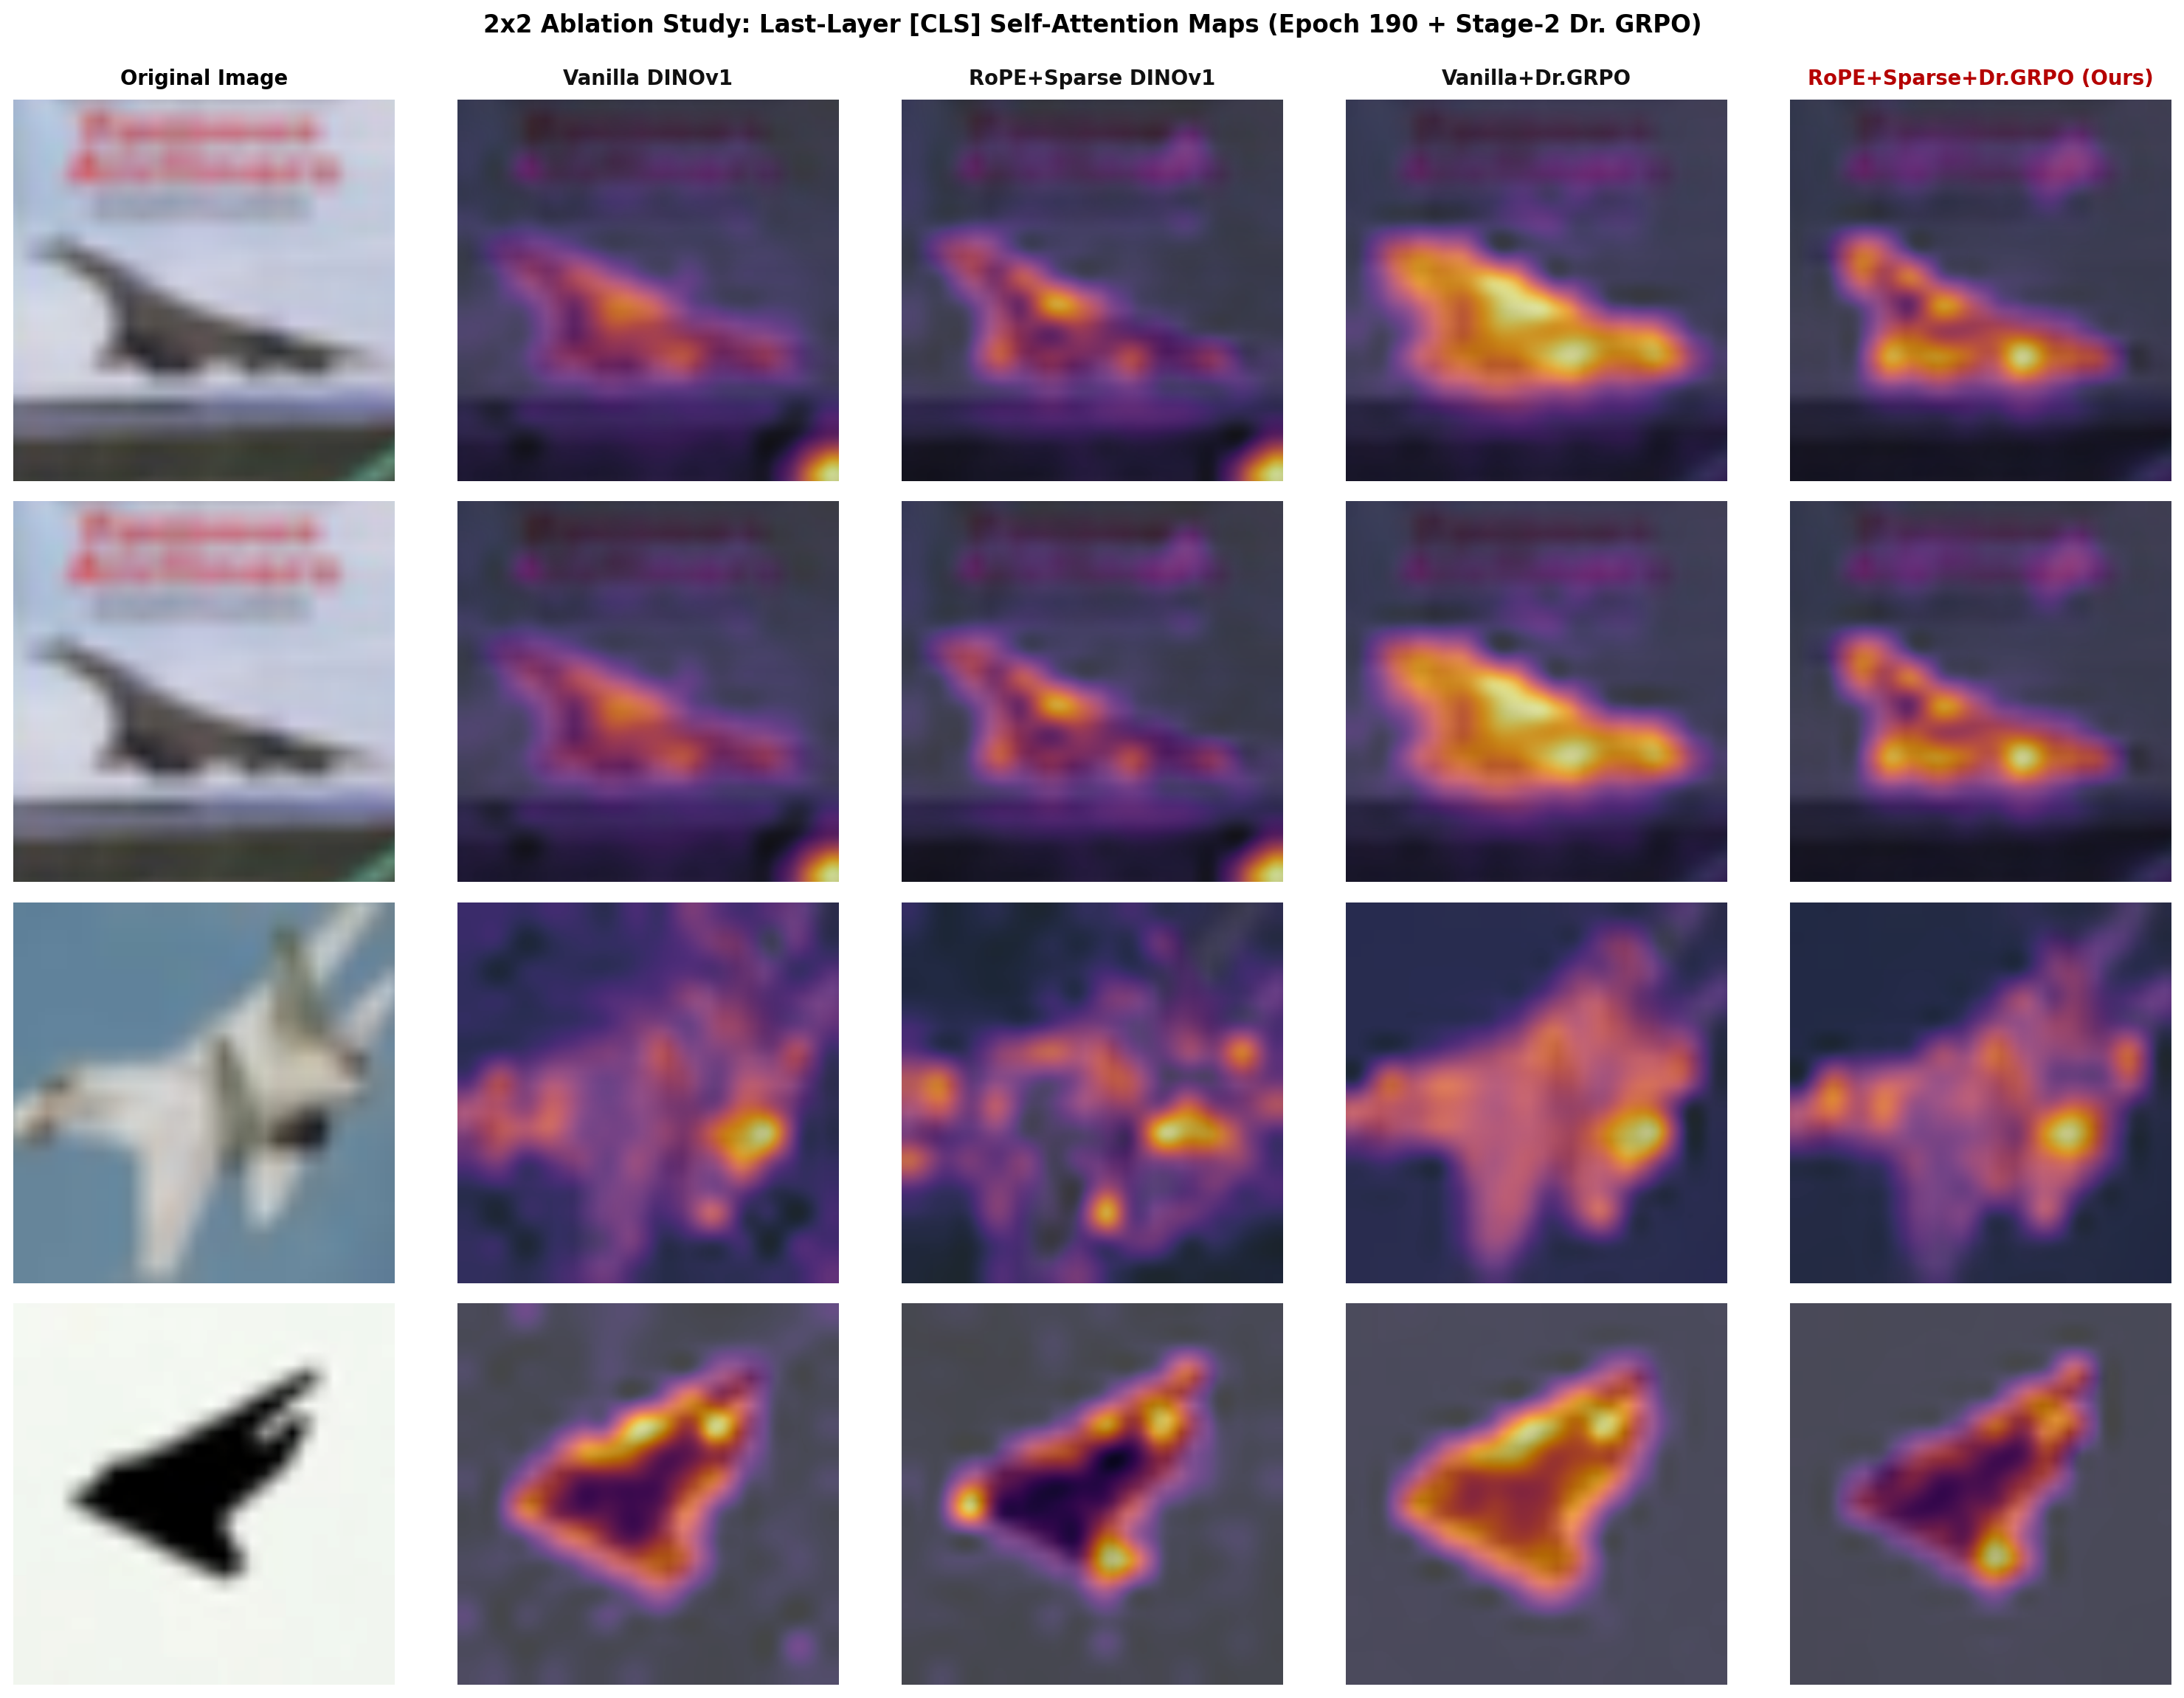

In [8]:
# ==============================================================================
# CELL 4: Full 2x2 Ablation Benchmark on CIFAR-10 (50k Train / 10k Val) & Visual Grid
# ==============================================================================
import os, subprocess, sys
from IPython.display import Image as IPyImage, Markdown, display

if os.path.exists("/content/DINOv1"):
    os.chdir("/content/DINOv1")
    if "/content/DINOv1" not in sys.path:
        sys.path.insert(0, "/content/DINOv1")

# Sync fix & CUDA AMP optimization onto Colab VM's eval/eval_ablation_2x2.py
with open("eval/eval_ablation_2x2.py", "r", encoding="utf-8") as _f:
    _esrc = _f.read()
_esrc = _esrc.replace(
    "data_path=args.data_path,\n        dataset_name=args.dataset,\n        batch_size=args.batch_size,\n        num_workers=0,",
    'eval_data_path=args.data_path,\n        eval_dataset=args.dataset,\n        batch_size=args.batch_size,\n        num_workers=2 if device.type == "cuda" else 0,',
)
_esrc = _esrc.replace(
    "target_sparsity: float = 0.35,\n) -> Tuple",
    "target_sparsity: float = 0.35,\n    compute_masks: bool = True,\n) -> Tuple",
)
_esrc = _esrc.replace(
    "        B_cur, N = cls_attn.shape",
    "        if not compute_masks:\n            continue\n        B_cur, N = cls_attn.shape",
)
_esrc = _esrc.replace(
    "model, train_loader, device, target_sparsity=args.target_sparsity\n",
    "model, train_loader, device, target_sparsity=args.target_sparsity, compute_masks=False\n",
)
with open("eval/eval_ablation_2x2.py", "w", encoding="utf-8") as _f:
    _f.write(_esrc)

CIFAR10_DIR = (
    "/content/fast_data/cifar10" if os.path.exists("/content") else "data/cifar10"
)

eval_cmd = [
    sys.executable,
    "-u",
    "eval/eval_ablation_2x2.py",
    "--data_path",
    CIFAR10_DIR,
    "--dataset",
    "cifar10",
    "--batch_size",
    "128",
    "--max_train_samples",
    "0",  # Full 50,000 CIFAR-10 train set matching report.md
    "--max_val_samples",
    "0",  # Full 10,000 CIFAR-10 test set matching report.md
]
print("Running full CIFAR-10 2x2 benchmark:", " ".join(eval_cmd), flush=True)
_p = subprocess.Popen(
    eval_cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1
)
for _line in _p.stdout:
    print(_line, end="", flush=True)
assert _p.wait() == 0, f"eval_ablation_2x2.py failed with code {_p.returncode}"

with open("output/ablation_2x2_results.md", "r", encoding="utf-8") as f:
    display(Markdown(f.read()))

display(IPyImage(filename="output/ablation_2x2_attention_grid.png"))

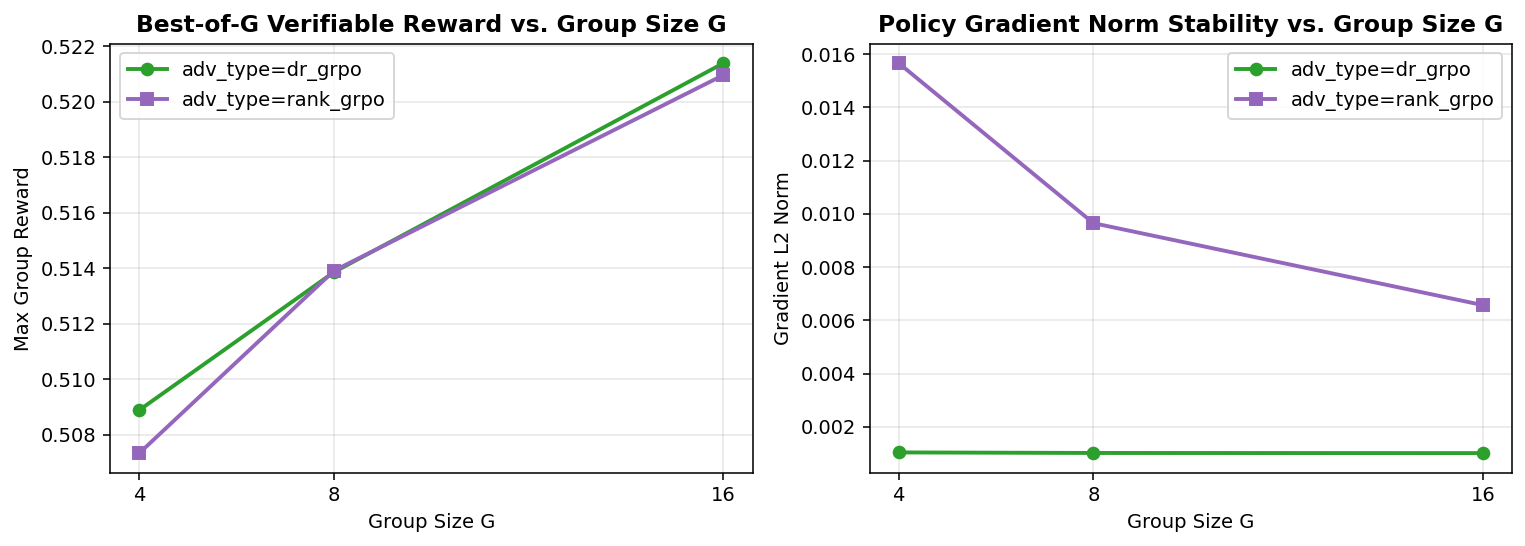

In [9]:
# ==============================================================================
# CELL 5: Group Size G in {4, 8, 16} & Advantage Type (dr_grpo vs rank_grpo) Ablation
# ==============================================================================
import os, sys, torch
import matplotlib.pyplot as plt

if os.path.exists("/content/DINOv1"):
    os.chdir("/content/DINOv1")
    if "/content/DINOv1" not in sys.path:
        sys.path.insert(0, "/content/DINOv1")

from losses.dr_grpo_loss import DrGRPOLoss

torch.manual_seed(42)
B, N, D = 16, 196, 384
dummy_probs = torch.sigmoid(torch.randn(B, N, requires_grad=True))
dummy_ref = torch.sigmoid(torch.randn(B, N))
dummy_feats = torch.randn(B, N, D)

group_sizes = [4, 8, 16]
adv_types = ["dr_grpo", "rank_grpo"]
ablation_stats = {adv: [] for adv in adv_types}

for adv in adv_types:
    for G in group_sizes:
        loss_fn = DrGRPOLoss(
            group_size=G, adv_type=adv, reward_mode="self_supervised_v1"
        )
        p = dummy_probs.detach().clone().requires_grad_(True)
        loss, info = loss_fn(
            policy_probs=p, ref_probs=dummy_ref, patch_features=dummy_feats
        )
        loss.backward()
        grad_norm = float(p.grad.norm().item())
        ablation_stats[adv].append((G, info["max_reward"], grad_norm))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=140)
for adv, marker, color in [("dr_grpo", "o", "#2ca02c"), ("rank_grpo", "s", "#9467bd")]:
    gs = [x[0] for x in ablation_stats[adv]]
    max_r = [x[1] for x in ablation_stats[adv]]
    gnorm = [x[2] for x in ablation_stats[adv]]
    axes[0].plot(
        gs, max_r, marker=marker, color=color, linewidth=2, label=f"adv_type={adv}"
    )
    axes[1].plot(
        gs, gnorm, marker=marker, color=color, linewidth=2, label=f"adv_type={adv}"
    )

axes[0].set_title("Best-of-G Verifiable Reward vs. Group Size G", fontweight="bold")
axes[0].set_xlabel("Group Size G")
axes[0].set_xticks(group_sizes)
axes[0].set_ylabel("Max Group Reward")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].set_title("Policy Gradient Norm Stability vs. Group Size G", fontweight="bold")
axes[1].set_xlabel("Group Size G")
axes[1].set_xticks(group_sizes)
axes[1].set_ylabel("Gradient L2 Norm")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig("output/ablation_group_size_adv_type.png", bbox_inches="tight")
plt.show()

In [10]:
# ==============================================================================
# CELL 6: Persistent Storage Sync & Auto-Shutdown to Protect 200 CCU Budget
# ==============================================================================
import os, shutil

AUTO_DISCONNECT = (
    False  # Set to True after verifying/downloading results to release GPU runtime
)
DRIVE_BACKUP_DIR = os.environ.get(
    "DINO_DRIVE_BACKUP", "/content/drive/MyDrive/DINOv1_GRPO_Backup"
)

if os.path.exists("/content/drive/MyDrive"):
    os.makedirs(DRIVE_BACKUP_DIR, exist_ok=True)
    for folder in ["output", "cp/checkpoints_def_grpo", "cp/checkpoints_rop_grpo"]:
        if os.path.exists(folder):
            dst = os.path.join(DRIVE_BACKUP_DIR, folder)
            shutil.copytree(folder, dst, dirs_exist_ok=True)
            print(f"Synced {folder} -> {dst}")
else:
    print(
        "Note: /content/drive/MyDrive is not mounted. Keep runtime alive until you inspect/download output/."
    )

if AUTO_DISCONNECT:
    try:
        from google.colab import runtime

        print("Releasing Google Colab GPU runtime to protect CCU balance...")
        runtime.unassign()
    except Exception as exc:
        print(f"Local execution detected (not on Colab runtime): {exc}")

Synced output -> /content/drive/MyDrive/DINOv1_GRPO_Backup/output
Synced cp/checkpoints_def_grpo -> /content/drive/MyDrive/DINOv1_GRPO_Backup/cp/checkpoints_def_grpo
Synced cp/checkpoints_rop_grpo -> /content/drive/MyDrive/DINOv1_GRPO_Backup/cp/checkpoints_rop_grpo
